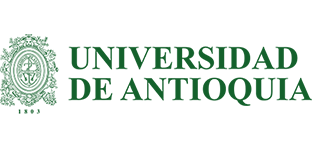

### **Universidad de Antioquia**

### **Facultad de Ingeniería**

### **Bioingeniería**

### **TEORÍA DE MODELOS Y SIMULACIÓN DE SISTEMAS**

---

# **Sesión 1: Introducción a Python**

## **Taller Práctico: Análisis de Señales en Bioingeniería**

**Semestre:** 2026 - 2

**Nombre:**

**Documento:**

---

### **Objetivos**

- Aplicar los conceptos de generación, manipulación y visualización de señales en Python (NumPy y Matplotlib) a un caso simulado de Bioingeniería.

- Implementar estructuras de control de flujo (ciclos for) para el análisis punto a punto de señales.

- Construir funciones que integren la generación de señales, el análisis estadístico (RMS, correlación) y la representación gráfica de resultados.

- Interpretar los resultados obtenidos en el contexto de una aplicación biomédica real.

---


## **Ejercicio Propuesto**

**Contexto:** Un equipo de Bioingeniería de la Universidad de Antioquia está evaluando la fuerza de agarre (dinamometría) de dos voluntarios durante una prueba de resistencia muscular, con el fin de identificar los momentos en los que ambos presentan fatiga simultánea y caracterizar estadísticamente sus señales.

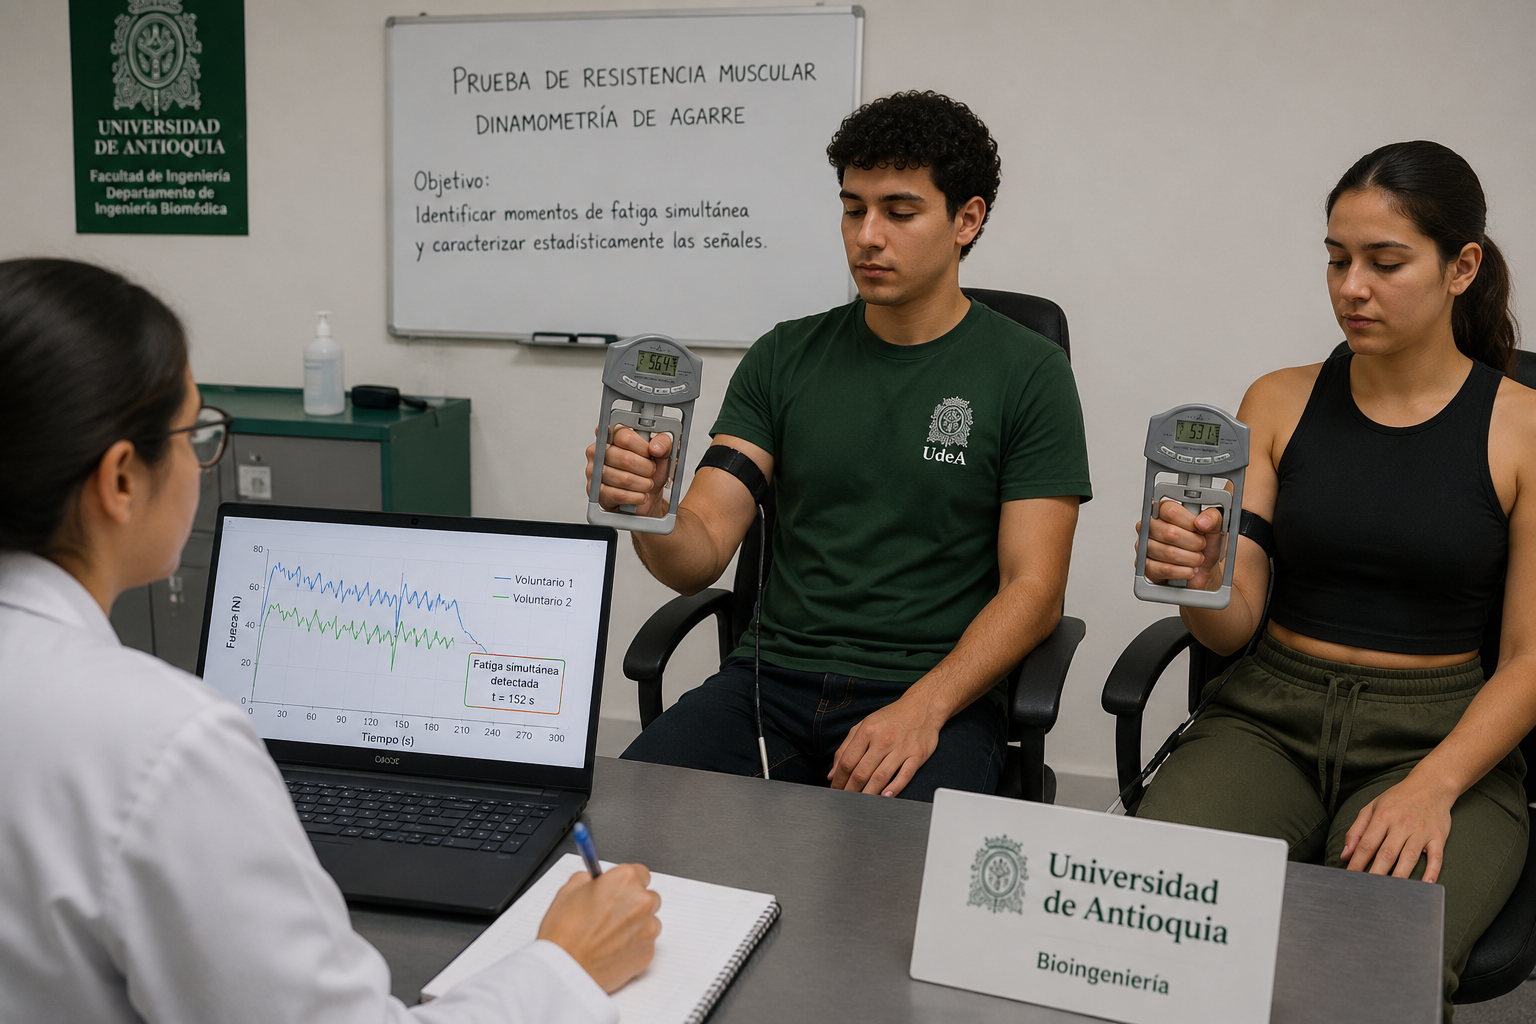

---

### **Importación de Librerías**

In [1]:
import numpy as np              # NumPy: manejo de vectores/arreglos y operaciones numéricas
import matplotlib.pyplot as plt # Matplotlib: para graficar las señales


---
Elabore una función llamada **analisis_fatiga** que reciba como parámetros de entrada la amplitud y el período de la señal de cada voluntario (a1, t1, a2, t2) y un valor de umbral de fatiga, y que realice las siguientes tareas:

**A.** Cree el vector de tiempo considerando un total de 30 segundos con una frecuencia de muestreo de 10 muestras/segundo. Construya las señales senoidales de fuerza de cada voluntario, teniendo en cuenta que la amplitud ingresada se mantiene durante los primeros 15 segundos y decae a la mitad en los 15 segundos restantes (simulando el efecto de la fatiga sobre la fuerza máxima).

**B.** Utilice un ciclo **for** para recorrer ambas señales y determinar los instantes de tiempo en los que ambos voluntarios están simultáneamente por debajo del umbral de fatiga ingresado. Almacene dichos instantes, junto con los valores correspondientes de cada señal, en variables nuevas.

**C.** Calcule el valor RMS de cada señal usando la ecuación:

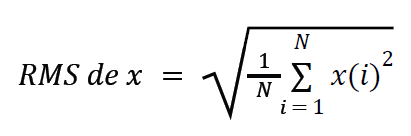

**D.** Calcule el coeficiente de correlación entre ambas señales usando np.corrcoef.

**E.** Construya una matriz de dimensión (2, N) que contenga los datos de ambos voluntarios (una fila por voluntario), usando **np.vstack**.

**F.** Grafique ambas señales en un mismo plano, resaltando con marcadores los instantes de fatiga simultánea encontrados en el numeral B, y trace una línea horizontal que represente el umbral. Incluya título, etiquetas de ejes y leyenda.

---

### **Solución**

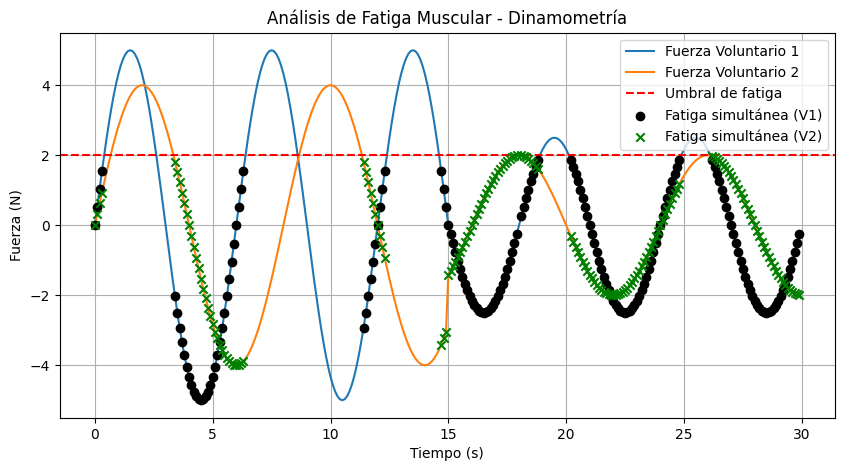

RMS Voluntario 1: 2.7951
RMS Voluntario 2: 2.2606
Coeficiente de correlación: -0.0676
Dimensión de la matriz de señales: (2, 300)
Instantes de fatiga simultánea (s): [ 0.   0.1  0.2  0.3  3.4  3.5  3.6  3.7  3.8  3.9  4.   4.1  4.2  4.3
  4.4  4.5  4.6  4.7  4.8  4.9  5.   5.1  5.2  5.3  5.4  5.5  5.6  5.7
  5.8  5.9  6.   6.1  6.2  6.3 11.4 11.5 11.6 11.7 11.8 11.9 12.  12.1
 12.2 12.3 14.7 14.8 14.9 15.  15.1 15.2 15.3 15.4 15.5 15.6 15.7 15.8
 15.9 16.  16.1 16.2 16.3 16.4 16.5 16.6 16.7 16.8 16.9 17.  17.1 17.2
 17.3 17.4 17.5 17.6 17.7 17.8 17.9 18.1 18.2 18.3 18.4 18.5 18.6 18.7
 18.8 20.2 20.3 20.4 20.5 20.6 20.7 20.8 20.9 21.  21.1 21.2 21.3 21.4
 21.5 21.6 21.7 21.8 21.9 22.  22.1 22.2 22.3 22.4 22.5 22.6 22.7 22.8
 22.9 23.  23.1 23.2 23.3 23.4 23.5 23.6 23.7 23.8 23.9 24.  24.1 24.2
 24.3 24.4 24.5 24.6 24.7 24.8 26.2 26.3 26.4 26.5 26.6 26.7 26.8 26.9
 27.  27.1 27.2 27.3 27.4 27.5 27.6 27.7 27.8 27.9 28.  28.1 28.2 28.3
 28.4 28.5 28.6 28.7 28.8 28.9 29.  29.1 29.2 29.3 29

In [2]:
def analisis_fatiga(a1, t1, a2, t2, umbral):
    """
    Analiza la fatiga muscular de dos voluntarios a partir de señales
    senoidales de fuerza (dinamometría).

    Parámetros
    ----------
    a1, t1 : amplitud y período (s) de la señal del voluntario 1
    a2, t2 : amplitud y período (s) de la señal del voluntario 2
    umbral : valor de fuerza por debajo del cual se considera fatiga
    """

    # ------------------------------------------------------------------
    # A. Construcción del vector de tiempo y de las señales de fuerza
    # ------------------------------------------------------------------
    fs = 10                              # Frecuencia de muestreo: 10 muestras/segundo
    duracion = 30                        # Duración total de la prueba: 30 segundos
    t = np.arange(0, duracion, 1 / fs)   # Vector de tiempo de 0 a 30 s (paso = 1/fs)

    # Amplitud variable en el tiempo: se mantiene el valor ingresado durante
    # los primeros 15 s y decae a la mitad durante los 15 s restantes.
    amp1 = np.where(t < 15, a1, a1 / 2)  # Amplitud del voluntario 1 por muestra
    amp2 = np.where(t < 15, a2, a2 / 2)  # Amplitud del voluntario 2 por muestra

    # Señales senoidales de fuerza: A(t) * sin(2*pi*t/T)
    senal1 = amp1 * np.sin(2 * np.pi * t / t1)  # Señal de fuerza - voluntario 1
    senal2 = amp2 * np.sin(2 * np.pi * t / t2)  # Señal de fuerza - voluntario 2

    # ------------------------------------------------------------------
    # B. Ciclo for: instantes de fatiga simultánea (ambas señales < umbral)
    # ------------------------------------------------------------------
    tiempos_fatiga = []      # Instantes de tiempo con fatiga simultánea
    valores_fatiga1 = []     # Valores de la señal 1 en esos instantes
    valores_fatiga2 = []     # Valores de la señal 2 en esos instantes

    for i in range(len(t)):                       # Recorre muestra a muestra
        if senal1[i] < umbral and senal2[i] < umbral:  # Fatiga simultánea
            tiempos_fatiga.append(t[i])            # Guarda el instante de tiempo
            valores_fatiga1.append(senal1[i])      # Guarda el valor de la señal 1
            valores_fatiga2.append(senal2[i])      # Guarda el valor de la señal 2

    # Se convierten las listas a arreglos de NumPy para facilitar su manejo
    tiempos_fatiga = np.array(tiempos_fatiga)
    valores_fatiga1 = np.array(valores_fatiga1)
    valores_fatiga2 = np.array(valores_fatiga2)

    # ------------------------------------------------------------------
    # C. Valor RMS de cada señal: RMS = sqrt(promedio(señal^2))
    # ------------------------------------------------------------------
    rms1 = np.sqrt(np.mean(senal1 ** 2))   # RMS de la señal del voluntario 1
    rms2 = np.sqrt(np.mean(senal2 ** 2))   # RMS de la señal del voluntario 2

    # ------------------------------------------------------------------
    # D. Coeficiente de correlación entre ambas señales
    # ------------------------------------------------------------------
    matriz_corr = np.corrcoef(senal1, senal2)  # Matriz de correlación 2x2
    correlacion = matriz_corr[0, 1]            # Coeficiente de correlación cruzada

    # ------------------------------------------------------------------
    # E. Matriz (2, N) con ambas señales apiladas por filas
    # ------------------------------------------------------------------
    matriz_senales = np.vstack((senal1, senal2))  # Fila 0: voluntario 1, fila 1: voluntario 2

    # ------------------------------------------------------------------
    # F. Gráfica de ambas señales con instantes de fatiga y umbral
    # ------------------------------------------------------------------
    plt.figure(figsize=(10, 5))                                    # Tamaño de la figura
    plt.plot(t, senal1, label="Fuerza Voluntario 1")                # Señal del voluntario 1
    plt.plot(t, senal2, label="Fuerza Voluntario 2")                # Señal del voluntario 2
    plt.axhline(umbral, color="red", linestyle="--",
                label="Umbral de fatiga")                           # Línea horizontal del umbral
    plt.scatter(tiempos_fatiga, valores_fatiga1, color="black",
                marker="o", zorder=5,
                label="Fatiga simultánea (V1)")                     # Puntos de fatiga - V1
    plt.scatter(tiempos_fatiga, valores_fatiga2, color="green",
                marker="x", zorder=5,
                label="Fatiga simultánea (V2)")                     # Puntos de fatiga - V2
    plt.title("Análisis de Fatiga Muscular - Dinamometría")         # Título de la gráfica
    plt.xlabel("Tiempo (s)")                                        # Etiqueta eje X
    plt.ylabel("Fuerza (N)")                                        # Etiqueta eje Y
    plt.legend()                                                    # Muestra la leyenda
    plt.grid(True)                                                  # Cuadrícula de apoyo visual
    plt.show()                                                      # Renderiza la gráfica

    # ------------------------------------------------------------------
    # Resultados impresos en pantalla
    # ------------------------------------------------------------------
    print(f"RMS Voluntario 1: {rms1:.4f}")
    print(f"RMS Voluntario 2: {rms2:.4f}")
    print(f"Coeficiente de correlación: {correlacion:.4f}")
    print(f"Dimensión de la matriz de señales: {matriz_senales.shape}")
    print(f"Instantes de fatiga simultánea (s): {tiempos_fatiga}")

    # Se retornan los resultados por si se requieren para otros análisis
    return {
        "tiempo": t,
        "senal1": senal1,
        "senal2": senal2,
        "tiempos_fatiga": tiempos_fatiga,
        "rms1": rms1,
        "rms2": rms2,
        "correlacion": correlacion,
        "matriz_senales": matriz_senales,
    }


# Ejemplo de ejecución (según la Pista del Resultado Esperado)
resultados = analisis_fatiga(5, 6, 4, 8, 2)


---

### **Análisis del Ejercicio Propuesto**

Adicionalmente, responda:

* ¿Por qué la amplitud decae a partir de los 15 segundos y qué representa esto fisiológicamente?

* ¿Qué indica un coeficiente de correlación cercano a 0 entre las dos señales?

**Respuestas:**

- **¿Por qué la amplitud decae a partir de los 15 segundos y qué representa esto fisiológicamente?**
  La amplitud decae porque simula la **fatiga muscular**: al mantener una contracción sostenida durante la prueba de resistencia, se agotan progresivamente las reservas energéticas del músculo (ATP y glucógeno) y se acumulan metabolitos como el ácido láctico, lo que reduce la capacidad del músculo para generar la misma fuerza máxima. Por eso, en los primeros 15 segundos la fuerza se mantiene en su amplitud original, y en los siguientes 15 segundos (cuando aparece la fatiga) la fuerza máxima que puede ejercer el voluntario disminuye a la mitad.

- **¿Qué indica un coeficiente de correlación cercano a 0 entre las dos señales?**
  Un coeficiente de correlación cercano a 0 indica que **no existe una relación lineal significativa** entre las señales de fuerza de los dos voluntarios; es decir, el comportamiento (subidas y bajadas) de la fuerza de un voluntario no permite predecir el comportamiento del otro. Esto es esperable si ambas señales tienen periodos (frecuencias) distintos, ya que sus oscilaciones no están sincronizadas entre sí, aunque ambas puedan presentar fatiga de forma independiente.


---

### **Pista del Resultado Esperado**

*(Para verificar, como ejemplo de la implementación de la función)*.

Al ejecutar **analisis_fatiga(5, 6, 4, 8, 2)** se debe obtener, impreso en pantalla:

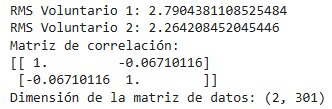

Y una gráfica con dos señales senoidales que tienen mayor amplitud en los primeros 15 segundos y luego se reducen a la mitad, una línea horizontal negra en y = 2 marcando el umbral, y marcadores rojos (x) y verdes (o) agrupados en los tramos donde ambas curvas caen simultáneamente por debajo de esa línea (se generan 171 coincidencias en total con estos parámetros). Así:

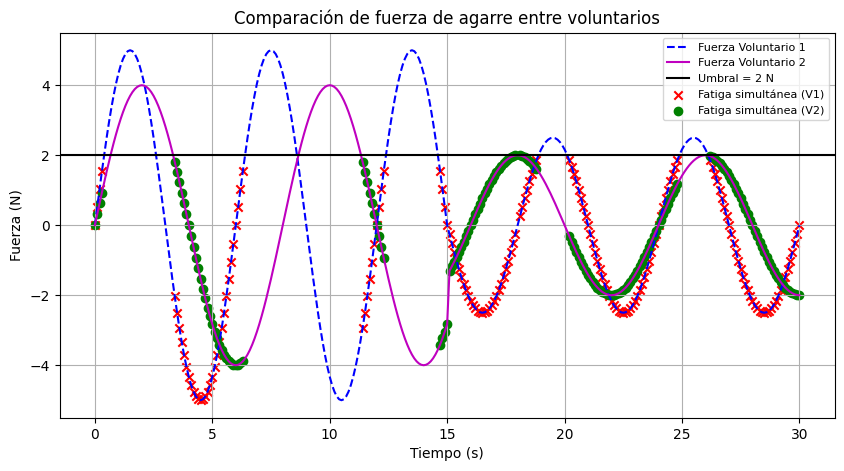

